John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

# Gradient boosting ablation: all songs in the last 60 s

Predicts a focal male's next song type (UST) with **gradient boosting (XGBoost)** instead of Random Forest.
Same layout as the RF notebook (packages → load data → lookup → class counts → modelling → accuracies → export), with these differences:

* **All model training happens in one cell: the ablation cell.** Every other cell only loads, prepares, checks, plots or exports.
* **Predictors are switched in the Settings cell** by editing named predictor groups and ablation sets. Every column comes from the existing `*_song_type_id_frequency.csv` files.
* Hyperparameter grid search is replaced by named GB options plus early stopping, which is where most of the speed-up comes from.
* Two CSVs are written in the same formats as `rf_All_songs_in_last_60s_test_accuracies.csv` and `..._song_accuracies.csv`.

# Import Packages

In [1]:
# install.packages(c("tidyverse", "xgboost"))
# install.packages(c("future", "furrr"))   # optional: trains the focal males in parallel
library(tidyverse)
library(xgboost)

Warning message:
"package 'tidyverse' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'tibble' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'readr' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'lubridate' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<

# Settings

Everything you are likely to change is in this one cell.

**Switching predictors**

1. `PREDICTOR_GROUPS` maps a group name to one or more regular expressions that are matched against the CSV column names. `{m}` is replaced by the focal male's number (`male_number` in the CSV), so `^M{m}_[12]_last_UST$` becomes `^M1_[12]_last_UST$` for LbOW. A pattern starting with `-` removes matches from that group.
2. `ABLATION_SETS` lists which groups go into each model. The **name** of each set is written to the `model` column of the output CSVs.
3. Columns that would leak the answer (`M<k>_last_UST` equals the song being predicted, `does_it_match`, `number_of_matches`, ...) are always removed, even if a pattern matches them.

In [2]:
## ---------------- Paths ----------------
DATA_DIR      <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id"
ONLY_IDS      <- NULL            # e.g. c("LbOW", "YKY") to run a subset; NULL = every file in DATA_DIR
OUTPUT_DIR    <- "data/results"
RESULT_PREFIX <- "gb_ablation"   # -> gb_ablation_test_accuracies.csv, gb_ablation_song_accuracies.csv

## ---------------- Run settings ----------------
SEED                <- 42
TRAIN_PROP          <- 0.7       # outer train/test split (stratified by song type), same for every ablation set
VAL_FRAC            <- 0.2       # inner validation split of the training data, used only for early stopping
REFIT_ON_FULL_TRAIN <- TRUE      # after early stopping, refit on all training rows with the best number of rounds
MIN_NONZERO         <- 3         # drop a predictor column if fewer than this many training rows are non-zero
DROP_NA_ROWS        <- FALSE     # FALSE: keep rows with NA predictors (XGBoost handles NA). TRUE: mimic the RF notebook's drop_na()
INCLUDE_BASELINE    <- TRUE      # also report the majority-class baseline for every male
IMPORTANCE_TOP_N    <- 20        # features kept per model for the importance plot (kept in memory, not exported)
N_WORKERS           <- max(1L, min(parallel::detectCores() - 1L, 4L))   # 1 = sequential (needs no extra packages)

## ---------------- Gradient boosting options ----------------
## Pick which to run with ACTIVE_OPTIONS. Each one multiplies the run time, so keep one unless you are comparing.
GB_OPTIONS <- list(
  xgb_shallow = list(label = "XGBoost (shallow)", max_rounds = 300L, early_stop = 20L,
    params = list(eta = 0.10, max_depth = 3, min_child_weight = 0.5, subsample = 0.8,
                  colsample_bytree = 0.5, lambda = 5, max_bin = 64))
)
ACTIVE_OPTIONS <- c("xgb_shallow")      # e.g. c("xgb_shallow", "xgb_deep") to compare

## ---------------- Predictor groups (regex on CSV column names; {m} = focal male number) ----------------
PREDICTOR_GROUPS <- list(
  own_last_ust                = "^M{m}_[12]_last_UST$",                       # own 1st and 2nd last song type
  own_last_time               = "^time_since_M{m}_[12]_last_song$",           # time since own 1st and 2nd last song
  own_third                   = c("^M{m}_3_last_UST$", "^time_since_M{m}_3_last_song$"),
  heard_last_60s              = "^n_ust_\\d+_window$",                        # neighbours' songs per type in the last 60 s
  heard_since_own_song        = c("^n_ust_\\d+$", "^n_ust_total$"),           # neighbours' songs per type since own last song
  heard_from_attention_target = "^n_ust_\\d+_target_window$",
  heard_from_other_neighbours = "^n_ust_\\d+_others_window$",
  attention_scores            = c("^Attention_on_M\\d$", "^highest_attention$", "^attention_target_male_number$"),
  neighbour_last_ust          = c("^M\\d_[12]_last_UST$", "-^M{m}_[12]_last_UST$"),
  neighbour_last_time         = c("^time_since_M\\d_[12]_last_song$", "-^time_since_M{m}_[12]_last_song$"),
  neighbour_most_common_60s   = "^M\\d_[123]_highest_UST_60_seconds$",
  shared_songs_60s            = "^M\\d_last_60_seconds_shared_songs$",
  time_of_day                 = "^time_rel_sunrise$",
  distances                   = "^D_M{m}_M\\d$"
)

## ---------------- Ablation sets (name -> groups). The name becomes the `model` column ----------------
ABLATION_SETS <- list(
  "Own last songs"                = c("own_last_ust"),
  "Own song history"              = c("own_last_ust", "own_last_time"),
  "All songs in last 60s"         = c("own_last_ust", "own_last_time", "heard_last_60s"),   # direct counterpart of the RF notebook
  "All songs since last own song" = c("own_last_ust", "own_last_time", "heard_since_own_song"),
  "Last song from each neighbour" = c("own_last_ust", "own_last_time", "neighbour_last_ust", "neighbour_last_time"),
  "Most common songs"             = c("own_last_ust", "own_last_time", "neighbour_most_common_60s"),
  "Attention 60s"                 = c("own_last_ust", "own_last_time", "attention_scores",
                                      "heard_from_attention_target", "heard_from_other_neighbours"),
  "Own history + time of day"     = c("own_last_ust", "own_last_time", "time_of_day")
)
ADD_LEAVE_ONE_OUT <- FALSE   # TRUE adds "Full minus <group>" sets for every group in FULL_GROUPS (true ablation, slower)
FULL_GROUPS <- c("own_last_ust", "own_last_time", "heard_last_60s", "neighbour_last_ust",
                 "neighbour_last_time", "attention_scores", "time_of_day")
if (ADD_LEAVE_ONE_OUT) {
  ABLATION_SETS[["Full"]] <- FULL_GROUPS
  for (g in FULL_GROUPS) ABLATION_SETS[[paste("Full minus", g)]] <- setdiff(FULL_GROUPS, g)
}

## ---------------- Column handling ----------------
# Columns encoded as categories (one-hot). Everything else is numeric.
CATEGORICAL_REGEX <- paste(c("_last_UST$", "_highest_UST_60_seconds$", "^attention_target_male_number$"), collapse = "|")
# Never used as predictors. M<k>_last_UST equals the target song (checked: 100% identical in LbOW).
NON_PREDICTORS_REGEX <- paste(c("^UST$", "^M\\d_last_UST$", "^number_of_matches$", "^does_it_match$",
                                "^DateTime$", "^ID$", "^male_number$", "^attention_target_id$"), collapse = "|")

stopifnot(all(unlist(ABLATION_SETS) %in% names(PREDICTOR_GROUPS)), all(ACTIVE_OPTIONS %in% names(GB_OPTIONS)))

## Gradient boosting options

| Option | Key settings | Why you might choose it | Risk |
|---|---|---|---|
| **`xgb_shallow`** (recommended) | depth 3, η 0.1, λ 5, 50% column sampling, early stopping | Each model has about 500 to 1,500 training rows, 18 to 28 imbalanced classes and a few hundred sparse count features. Shallow, L2-regularised trees stay stable here. They also match the project's finding that a few own-history features dominate. Early stopping replaces the 25-point × 5-fold RF tuning grid. | May miss higher-order interactions (e.g. neighbour song × timing). |
| `xgb_stumps_slow` | depth 2, η 0.05, λ 10, 30% column sampling | Most conservative. It builds a nearly additive model, which is useful for checking whether interactions matter at all. | Needs about twice as many rounds, so it is the slowest option. |
| `xgb_deep` | depth 6, η 0.1, λ 1 | Can pick up interactions between own history and neighbour songs. | Overfits easily at this sample size. Treat as an upper-capacity check. |

Considered but not implemented: LightGBM (leaf-wise growth gives no speed advantage below ~2k rows, `min_data_in_leaf` clashes with singleton song types, and the Windows install is more fragile) and CatBoost (native categorical handling is attractive for UST codes, but multiclass is slower and the R install is awkward).

**Suggested workflow:** run `xgb_shallow` on all ablation sets. If you want to compare options, set `ACTIVE_OPTIONS` to all three but restrict `ABLATION_SETS` to `"All songs in last 60s"` first. Compare using the `model_type` column in the output.

# Load data

In [3]:
files <- list.files(DATA_DIR, pattern = "\\y.csv$", full.names = TRUE)
data_list <- map(files, ~ read_csv(.x, show_col_types = FALSE, progress = FALSE))
names(data_list) <- map_chr(data_list, ~ as.character(unique(.x$ID))[1])
if (!is.null(ONLY_IDS)) data_list <- data_list[names(data_list) %in% ONLY_IDS]
focal_ids <- names(data_list)

# A lookup table to easily access IDs / ID numbers for each neighbourhood
focal_males <- tibble::tribble(
    ~neighbourhood, ~male_number, ~ID,
    "north",  "1", "LbOW",
    "north",  "2", "RbDgY",
    "north",  "3", "YKY",
    "north",  "4", "TbTbLg",
    "north",  "5", "DgTbO",
    "north",  "6", "RRO",
    "centre", "1", "TbWY",
    "centre", "2", "KRDg",
    "centre", "3", "OPR",
    "centre", "4", "WLpTb",
    "centre", "5", "KLgK",
    "centre", "6", "DgTbO"
)

tibble(ID = focal_ids,
       rows = map_int(data_list, nrow),
       cols = map_int(data_list, ncol),
       song_types = map_int(data_list, ~ n_distinct(.x$UST, na.rm = TRUE)))

ID,rows,cols,song_types
<chr>,<int>,<int>,<int>
DgTbO,2166,360,28
KLgK,516,363,19
KRDg,1021,363,26
LbOW,699,362,18
RbDgY,656,362,21
RRO,535,362,19
TbTbLg,734,362,19
TbWY,604,363,17
WLpTb,481,363,21


# Song type counts (training and testing data combined)

In [4]:
song_type_counts <- imap(data_list, function(d, id) {
    d %>% count(UST, name = "n") %>% mutate(percent = 100 * n / sum(n), ID = id) %>% arrange(desc(n))
})
bind_rows(song_type_counts) %>% group_by(ID) %>% slice_head(n = 3) %>% ungroup()   # top 3 song types per male

UST,n,percent,ID
<dbl>,<int>,<dbl>,<chr>
33,399,18.421053,DgTbO
10,286,13.204063,DgTbO
20,256,11.819021,DgTbO
4,77,14.922481,KLgK
10,57,11.046512,KLgK
8,48,9.302326,KLgK
9,135,13.222331,KRDg
28,100,9.794319,KRDg
20,89,8.716944,KRDg


# Predictor check (no training)

Shows how many raw columns each ablation set resolves to for each male. Use this after editing `PREDICTOR_GROUPS` or `ABLATION_SETS`. A zero means a pattern matched nothing for that male. Dropped leaky columns are listed.

In [5]:
# ---- helpers used by the ablation cell (data handling only; no model fitting) ----
resolve_patterns <- function(patterns, all_cols, male_number) {
    patterns <- gsub("{m}", male_number, patterns, fixed = TRUE)
    keep <- character(0)
    for (p in patterns) {
        if (startsWith(p, "-")) keep <- keep[!grepl(substring(p, 2), keep)]
        else keep <- union(keep, grep(p, all_cols, value = TRUE))
    }
    keep
}

# Each group is resolved on its own, then the groups are unioned, so a "-" pattern in one group cannot remove another group's columns.
resolve_cols <- function(group_names, all_cols, male_number) {
    cols <- as.character(unique(unlist(lapply(group_names, function(g)
        resolve_patterns(PREDICTOR_GROUPS[[g]], all_cols, male_number)))))
    cols[!grepl(NON_PREDICTORS_REGEX, cols)]
}

encode_cat <- function(x, name, levels) {
    v <- as.character(x); v[is.na(v)] <- "missing"   # NB: xgboost feature names may not contain < [ ]
    m <- matrix(0, nrow = length(v), ncol = length(levels), dimnames = list(NULL, paste0(name, "=", levels)))
    idx <- match(v, levels); ok <- !is.na(idx)
    m[cbind(which(ok), idx[ok])] <- 1
    m
}

# Stratified hold-out: for each class with >= min_n rows, hold out round(frac * n) rows (at least 1, never all)
strat_holdout <- function(y, frac, min_n) {
    out <- integer(0)
    for (cl in unique(y)) {
        idx <- which(y == cl); n <- length(idx)
        if (n >= min_n) out <- c(out, idx[sample.int(n, min(n - 1L, max(1L, round(frac * n))))])
    }
    sort(out)
}

predict_classes <- function(bst, X, K, iter_range = NULL) {
    dm <- xgb.DMatrix(data = X)
    p <- if (is.null(iter_range)) predict(bst, dm) else predict(bst, dm, iterationrange = iter_range)
    if (is.null(dim(p))) p <- matrix(p, ncol = K, byrow = TRUE)   # older xgboost returns a flat vector
    max.col(p, ties.method = "first") - 1L
}

# Builds the two result tables (formats match the RF result CSVs)
score_preds <- function(id, cfg, mtype, y_true, pred, y_levels, n_full) {
    test <- tibble(ID = id, estimated_accuracy = mean(pred == y_true), model = cfg, model_type = mtype)
    song <- tibble(UST = y_levels[y_true + 1L], correct = pred == y_true) %>%
        group_by(UST) %>% summarise(estimated_accuracy = mean(correct), .groups = "drop") %>%
        arrange(desc(estimated_accuracy)) %>%
        mutate(ID = id, model = cfg, n = as.integer(n_full[as.character(UST)]), model_type = mtype) %>%
        select(ID, UST, estimated_accuracy, model, n, model_type)
    list(test = test, song = song)
}

# ---- the check itself ----
check <- imap_dfr(data_list, function(d, id) {
    m <- d$male_number[1]
    map_dfr(names(ABLATION_SETS), function(cfg) {
        raw <- unique(unlist(lapply(ABLATION_SETS[[cfg]], function(g) resolve_patterns(PREDICTOR_GROUPS[[g]], names(d), m))))
        tibble(ID = id, model = cfg, columns = length(resolve_cols(ABLATION_SETS[[cfg]], names(d), m)),
               leaky_dropped = paste(setdiff(raw, resolve_cols(ABLATION_SETS[[cfg]], names(d), m)), collapse = ", "))
    })
})
print(check %>% select(-leaky_dropped) %>% pivot_wider(names_from = model, values_from = columns), width = Inf)
check %>% filter(leaky_dropped != "") %>% distinct(model, leaky_dropped)   # leaky columns that patterns matched and were removed

# A tibble: 10 × 9
   ID     `Own last songs` `Own song history` `All songs in last 60s`
   <chr>             <int>              <int>                   <int>
 1 DgTbO                 2                  4                      69
 2 KLgK                  2                  4                      69
 3 KRDg                  2                  4                      69
 4 LbOW                  2                  4                      69
 5 RbDgY                 2                  4                      69
 6 RRO                   2                  4                      69
 7 TbTbLg                2                  4                      69
 8 TbWY                  2                  4                      69
 9 WLpTb                 2                  4                      69
10 YKY                   2                  4                      69
   `All songs since last own song` `Last song from each neighbour`
                             <int>                           <int>
 1     

model,leaky_dropped
<chr>,<chr>


# Ablation: the only cell that trains models

For every focal male the cell:

1. Splits the data once, 70/30 and stratified by song type, with the same split for every ablation set, so differences between sets are not split noise.
2. Encodes the union of all needed columns once (song-type columns one-hot, counts and times numeric, NAs kept).
3. For each ablation set and active GB option, fits XGBoost with early stopping on a small validation split of the training data, then refits on the full training data with the best number of rounds.
4. Scores on the held-out 30%, producing overall and per-song-type accuracy, plus gain importance.

Males are independent, so they run in parallel when `N_WORKERS > 1`. If parallel setup fails, the cell falls back to sequential.

In [6]:
run_male <- function(id, df) {
    t0 <- Sys.time()
    set.seed(SEED)
    m <- df$male_number[1]
    df <- df[!is.na(df$UST), , drop = FALSE]

    cfg_cols  <- lapply(ABLATION_SETS, resolve_cols, all_cols = names(df), male_number = m)
    cfg_cols  <- cfg_cols[lengths(cfg_cols) > 0]
    used_cols <- unique(unlist(cfg_cols))
    if (DROP_NA_ROWS) df <- df[complete.cases(df[, used_cols, drop = FALSE]), , drop = FALSE]

    y_levels <- sort(unique(df$UST)); K <- length(y_levels)
    y        <- match(df$UST, y_levels) - 1L
    n_full   <- table(df$UST)

    # encode every needed column once
    blocks <- lapply(used_cols, function(cn) {
        if (grepl(CATEGORICAL_REGEX, cn)) {
            lv <- c(sort(unique(as.character(df[[cn]][!is.na(df[[cn]])]))), "missing")
            encode_cat(df[[cn]], cn, lv)
        } else matrix(as.numeric(df[[cn]]), ncol = 1, dimnames = list(NULL, cn))
    })
    X_all   <- do.call(cbind, blocks)
    orig_of <- sub("=.*$", "", colnames(X_all))

    # one outer split per male, shared by every ablation set
    test_idx  <- strat_holdout(y, 1 - TRAIN_PROP, min_n = 2)
    train_idx <- setdiff(seq_along(y), test_idx)
    ytr <- y[train_idx]; yte <- y[test_idx]

    nthread <- if (N_WORKERS > 1) 1L else max(1L, parallel::detectCores() - 1L)

    # ---- the model-fitting function ----
    fit_xgb <- function(Xtr, ytr, opt) {
        params <- c(opt$params, list(objective = "multi:softprob", num_class = K, eval_metric = "mlogloss",
                                     tree_method = "hist", nthread = nthread, seed = SEED))
        n_rounds <- opt$max_rounds
        val_pos <- strat_holdout(ytr, VAL_FRAC, min_n = 5)
        if (length(val_pos) >= 10) {
            dfit <- xgb.DMatrix(Xtr[-val_pos, , drop = FALSE], label = ytr[-val_pos])
            dval <- xgb.DMatrix(Xtr[val_pos, , drop = FALSE],  label = ytr[val_pos])
            args <- list(params = params, data = dfit, nrounds = opt$max_rounds,
                         early_stopping_rounds = opt$early_stop, verbose = 0)
            args[[if ("evals" %in% names(formals(xgb.train))) "evals" else "watchlist"]] <- list(val = dval)
            bst <- do.call(xgb.train, args)
            el  <- tryCatch(as.data.frame(bst$evaluation_log), error = function(e) NULL)
            n_rounds <- if (!is.null(el) && "val_mlogloss" %in% names(el)) which.min(el$val_mlogloss) else
                        tryCatch(max(1L, as.integer(bst$best_iteration)), error = function(e) opt$max_rounds)
            if (!REFIT_ON_FULL_TRAIN) return(list(bst = bst, iter_range = c(1L, n_rounds + 1L)))
        }
        bst <- xgb.train(params = params, data = xgb.DMatrix(Xtr, label = ytr),
                         nrounds = max(10L, ceiling(n_rounds * 1.1)), verbose = 0)
        list(bst = bst, iter_range = NULL)
    }

    tests <- list(); songs <- list(); imps <- list()
    add <- function(r) { tests[[length(tests) + 1]] <<- r$test; songs[[length(songs) + 1]] <<- r$song }

    for (cfg in names(cfg_cols)) {
        X    <- X_all[, orig_of %in% cfg_cols[[cfg]], drop = FALSE]
        Xtr  <- X[train_idx, , drop = FALSE]
        keep <- colSums(Xtr != 0, na.rm = TRUE) >= MIN_NONZERO      # prune empty/near-empty columns: big speed-up
        if (!any(keep)) next
        Xtr <- Xtr[, keep, drop = FALSE]; Xte <- X[test_idx, keep, drop = FALSE]

        for (opt_name in ACTIVE_OPTIONS) {
            opt <- GB_OPTIONS[[opt_name]]
            fit <- fit_xgb(Xtr, ytr, opt)
            pred <- predict_classes(fit$bst, Xte, K, fit$iter_range)
            add(score_preds(id, cfg, opt$label, yte, pred, y_levels, n_full))

            imp <- tryCatch(as_tibble(xgb.importance(feature_names = colnames(Xtr), model = fit$bst)), error = function(e) NULL)
            if (!is.null(imp) && nrow(imp) > 0) {
                imps[[length(imps) + 1]] <- imp %>%
                    mutate(feature = sub("=.*$", "", Feature)) %>%
                    group_by(feature) %>% summarise(gain = sum(Gain), .groups = "drop") %>%
                    arrange(desc(gain)) %>% slice_head(n = IMPORTANCE_TOP_N) %>%
                    mutate(ID = id, model = cfg, model_type = opt$label)
            }
        }
    }

    if (INCLUDE_BASELINE) {
        maj <- as.integer(names(which.max(table(ytr))))
        add(score_preds(id, "Baseline classifier", "Majority class", yte, rep(maj, length(yte)), y_levels, n_full))
    }

    list(test = bind_rows(tests), song = bind_rows(songs), imp = bind_rows(imps),
         secs = as.numeric(difftime(Sys.time(), t0, units = "secs")))
}

# ---- run every focal male ----
ablation_start <- Sys.time()
results <- NULL
if (N_WORKERS > 1 && length(focal_ids) > 1 && requireNamespace("furrr", quietly = TRUE)) {
    future::plan(future::multisession, workers = min(N_WORKERS, length(focal_ids)))
    results <- tryCatch(
        furrr::future_map2(focal_ids, unname(data_list[focal_ids]), run_male,
            .options = furrr::furrr_options(seed = TRUE, packages = c("dplyr", "tibble", "tidyr", "purrr", "xgboost"))),
        error = function(e) { message("Parallel run failed (", conditionMessage(e), "); running sequentially."); NULL })
    future::plan(future::sequential)
}
if (is.null(results)) results <- map2(focal_ids, unname(data_list[focal_ids]), run_male)
names(results) <- focal_ids

all_test_accuracies <- bind_rows(map(results, "test"))
all_song_accuracies <- bind_rows(map(results, "song"))
all_importance      <- bind_rows(map(results, "imp"))

cat("Ablation finished in", round(as.numeric(difftime(Sys.time(), ablation_start, units = "secs"))), "s;",
    "per-male seconds:", paste(names(results), round(map_dbl(results, "secs")), collapse = ", "), "\n")

Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'xgboost' was built under R version 4.5.3"
Warning message:
"package 'tibble' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'xgboost' was built under R version 4.5.3"
Warning message:
"package 'tibble' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'xgboost' was built under R

Ablation finished in 33 s; per-male seconds: DgTbO 15, KLgK 5, KRDg 8, LbOW 5, RbDgY 7, RRO 5, TbTbLg 7, TbWY 6, WLpTb 6, YKY 10 


# Results (no training below this point)

In [7]:
all_test_accuracies %>% arrange(estimated_accuracy, asc=FALSE)

ID,estimated_accuracy,model,model_type
<chr>,<dbl>,<chr>,<chr>
YKY,0.09433962,Baseline classifier,Majority class
TbTbLg,0.10360360,Baseline classifier,Majority class
WLpTb,0.11486486,Baseline classifier,Majority class
KRDg,0.13355049,Baseline classifier,Majority class
RbDgY,0.14141414,Baseline classifier,Majority class
KLgK,0.14838710,Baseline classifier,Majority class
KLgK,0.15483871,Own last songs,XGBoost (shallow)
KLgK,0.15483871,Attention 60s,XGBoost (shallow)
KLgK,0.16129032,All songs in last 60s,XGBoost (shallow)


In [8]:
# Mean test accuracy per ablation set across focal males, and gain over the majority-class baseline
baseline <- all_test_accuracies %>% filter(model == "Baseline classifier") %>% select(ID, baseline = estimated_accuracy)
summary_tbl <- all_test_accuracies %>%
    filter(model != "Baseline classifier") %>%
    left_join(baseline, by = "ID") %>%
    group_by(model, model_type) %>%
    summarise(mean_accuracy = mean(estimated_accuracy), sd = sd(estimated_accuracy),
              mean_gain_over_baseline = mean(estimated_accuracy - baseline), n_males = n(), .groups = "drop") %>%
    arrange(desc(mean_accuracy))
summary_tbl

model,model_type,mean_accuracy,sd,mean_gain_over_baseline,n_males
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>
All songs since last own song,XGBoost (shallow),0.2788829,0.06515599,0.12799353,10
Last song from each neighbour,XGBoost (shallow),0.2546270,0.06380764,0.10373769,10
Own song history,XGBoost (shallow),0.2530464,0.06070411,0.10215705,10
Own history + time of day,XGBoost (shallow),0.2525800,0.06599195,0.10169060,10
Attention 60s,XGBoost (shallow),0.2524856,0.06499231,0.10159623,10
Most common songs,XGBoost (shallow),0.2510391,0.05617861,0.10014970,10
Own last songs,XGBoost (shallow),0.2492795,0.05805081,0.09839019,10
All songs in last 60s,XGBoost (shallow),0.2445658,0.05411865,0.09367645,10


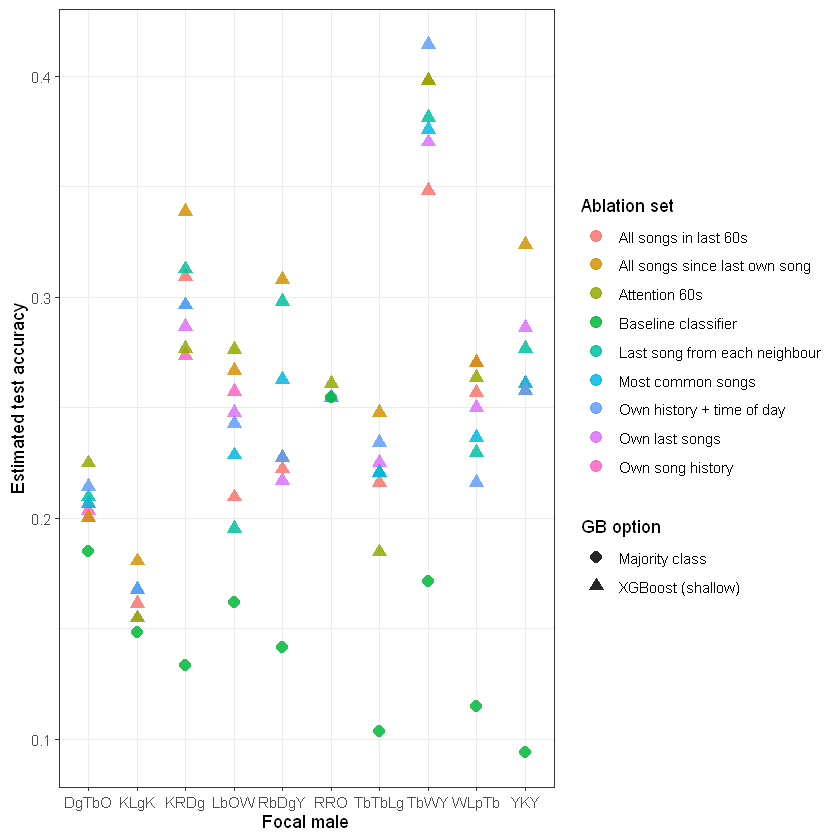

In [9]:
# Accuracy per focal male for each ablation set (cf. Figure 2 of the CPSC 4990 report)
ggplot(all_test_accuracies, aes(x = ID, y = estimated_accuracy, colour = model, shape = model_type)) +
    geom_point(size = 3, alpha = 0.85) +
    labs(x = "Focal male", y = "Estimated test accuracy", colour = "Ablation set", shape = "GB option") +
    theme_bw()

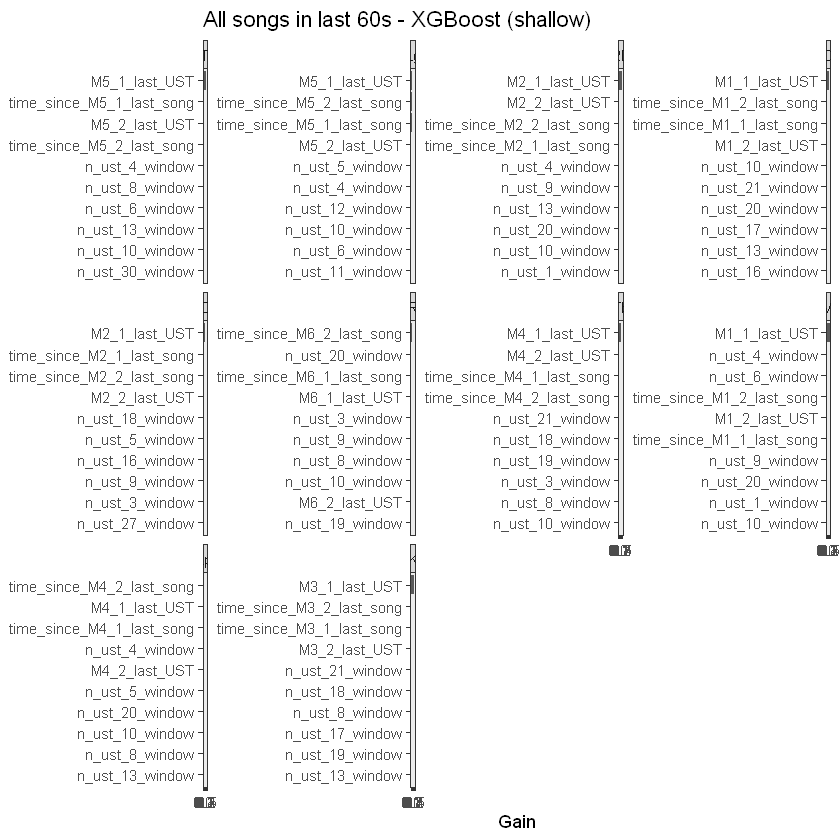

In [10]:
# Top features (summed gain over one-hot levels) for one ablation set
PLOT_MODEL  <- "All songs in last 60s"
PLOT_OPTION <- GB_OPTIONS[[ACTIVE_OPTIONS[1]]]$label

all_importance %>%
    filter(model == PLOT_MODEL, model_type == PLOT_OPTION) %>%
    group_by(ID) %>% slice_max(gain, n = 10, with_ties = FALSE) %>% ungroup() %>%
    mutate(feature = fct_reorder(paste(ID, feature, sep = "___"), gain)) %>%
    ggplot(aes(x = gain, y = feature)) +
    geom_col() +
    facet_wrap(~ ID, scales = "free_y") +
    scale_y_discrete(labels = function(x) sub("^.*___", "", x)) +
    labs(x = "Gain", y = NULL, title = paste(PLOT_MODEL, "-", PLOT_OPTION)) +
    theme_bw()

# Export results

In [11]:
dir.create(OUTPUT_DIR, recursive = TRUE, showWarnings = FALSE)

filename <- file.path(OUTPUT_DIR, paste0(RESULT_PREFIX, "_test_accuracies.csv"))
print(filename)
write_csv(all_test_accuracies, filename)     # columns: ID, estimated_accuracy, model, model_type

filename <- file.path(OUTPUT_DIR, paste0(RESULT_PREFIX, "_song_accuracies.csv"))
print(filename)
write_csv(all_song_accuracies, filename)     # columns: ID, UST, estimated_accuracy, model, n, model_type

[1] "data/results/gb_ablation_test_accuracies.csv"
[1] "data/results/gb_ablation_song_accuracies.csv"


## Notes on the data and outputs

* `M<k>_last_UST` is identical to `UST` in 100% of LbOW rows, so using it would leak the answer. The same applies to `does_it_match` and `number_of_matches`. They are excluded automatically (`NON_PREDICTORS_REGEX`).
* In the old notebook, `across(contains("UST"), as.factor)` also converted all the `n_ust_*` count columns to factors (`contains()` ignores case). Here counts stay numeric and only song-type columns are one-hot encoded.
* In the LbOW file, `M<k>_1/2/3_highest_UST_60_seconds` hold the same value in all three slots, so the second and third add nothing. This is worth checking in the feature-engineering code.
* The `n` column in the old song-accuracy CSV was joined from the training counts of the last male looped over, which is why it is mostly `NA`. Here `n` is the number of that song type in the male's full dataset.
* `model` is the ablation set name and `model_type` is the GB option (or `Majority class` for the baseline), so these files can be stacked with the RF results.